# Laporan Praktikum 1: Pemrograman Shared Memory dengan OpenMP

**Nama:** Zinniarethie Andari Kostiene  
**NIM:** 09011482528012  
**Kelas:** SKU5A  
**Kode asesmen:** A05 (Sub-CPMK 3.2)

Repositori: https://github.com/firehooman/Praktikum-1-Pemrograman-Shared-Memory-dengan-OpenMP

## 1. Tujuan

Praktikum ini bertujuan memparalelkan program serial dengan OpenMP, memverifikasi kebenaran hasilnya, dan mengukur pengaruh kebijakan scheduling pada beban yang tidak seragam. Dua program digunakan: perkalian matriks (Bagian A) dan penghitungan bilangan prima sampai 10⁷ (Bagian B).

## 2. Lingkungan dan Metode

**Tabel 1. Lingkungan**

| Prosesor | Core fisik | Core logis | Memori | Versi GCC | Opsi kompilasi |
|---|---|---|---|---|---|
| Intel Core i5-6200U @ 2,30 GHz | 2 | 4 | 3,8 GiB (terlihat di WSL) | 13.3.0 (Ubuntu 13.3.0-6ubuntu2~24.04.1) | `-O2 -fopenmp` |

Pengukuran dijalankan di Ubuntu 24.04 pada WSL di atas Windows. Waktu diukur dengan `omp_get_wtime()`. Setiap konfigurasi dijalankan 3 kali dan yang dilaporkan adalah median.

**Perkalian matriks.** Perulangan terluar (indeks `i`) diparalelkan dengan `#pragma omp parallel for` pada fungsi `matmul_paralel`. Ukuran matriks n = 1024; waktu serial di mesin ini sekitar 10 detik, sehingga syarat n = 1536 tidak berlaku. Jumlah thread yang diuji: 1, 2, 4, dan 8.

**Bilangan prima.** Perulangan utama diparalelkan dengan `#pragma omp parallel for reduction(+:jumlah) schedule(runtime)`. Kebijakan scheduling diatur lewat variabel `OMP_SCHEDULE` (static, dynamic dengan chunk 1000, dan guided). Hasil diperiksa terhadap nilai acuan 664.579.

Kode lengkap ada di bagian Lampiran.

## 3. Hasil

### 3.1 Perkalian matriks

Data mentah (`hasil/matmul.txt`):

In [ ]:
MATMUL = """n=1024 thread=1 serial=11.604 paralel=11.348 benar=ya
n=1024 thread=1 serial=10.626 paralel=10.615 benar=ya
n=1024 thread=1 serial=10.525 paralel=12.026 benar=ya
n=1024 thread=2 serial=13.828 paralel=9.112 benar=ya
n=1024 thread=2 serial=10.269 paralel=8.663 benar=ya
n=1024 thread=2 serial=10.271 paralel=8.534 benar=ya
n=1024 thread=4 serial=10.395 paralel=8.734 benar=ya
n=1024 thread=4 serial=10.233 paralel=8.687 benar=ya
n=1024 thread=4 serial=10.724 paralel=9.596 benar=ya
n=1024 thread=8 serial=11.005 paralel=9.039 benar=ya
n=1024 thread=8 serial=10.077 paralel=8.287 benar=ya
n=1024 thread=8 serial=10.361 paralel=8.762 benar=ya"""
print(MATMUL)

n=1024 thread=1 serial=11.604 paralel=11.348 benar=ya
n=1024 thread=1 serial=10.626 paralel=10.615 benar=ya
n=1024 thread=1 serial=10.525 paralel=12.026 benar=ya
n=1024 thread=2 serial=13.828 paralel=9.112 benar=ya
n=1024 thread=2 serial=10.269 paralel=8.663 benar=ya
n=1024 thread=2 serial=10.271 paralel=8.534 benar=ya
n=1024 thread=4 serial=10.395 paralel=8.734 benar=ya
n=1024 thread=4 serial=10.233 paralel=8.687 benar=ya
n=1024 thread=4 serial=10.724 paralel=9.596 benar=ya
n=1024 thread=8 serial=11.005 paralel=9.039 benar=ya
n=1024 thread=8 serial=10.077 paralel=8.287 benar=ya
n=1024 thread=8 serial=10.361 paralel=8.762 benar=ya


In [ ]:

import re, statistics
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

def fmt(x, d=3):
    return f"{x:.{d}f}".replace(".", ",")

def tabel(header, rows):
    t = "| " + " | ".join(header) + " |\n"
    t += "|" + "|".join(["---"] * len(header)) + "|\n"
    for r in rows:
        t += "| " + " | ".join(str(c) for c in r) + " |\n"
    display(Markdown(t))


**Tabel 2.** Perkalian matriks, n = 1024 (waktu dalam detik, median 3 pengulangan). Speedup = waktu serial / waktu paralel; efisiensi = speedup / jumlah thread.

In [ ]:
serial, paralel, benar = {}, {}, {}
pola = re.compile(r"thread=(\d+) serial=([\d.]+) paralel=([\d.]+) benar=(\w+)")
for baris in MATMUL.splitlines():
    m = pola.search(baris)
    t = int(m.group(1))
    serial.setdefault(t, []).append(float(m.group(2)))
    paralel.setdefault(t, []).append(float(m.group(3)))
    benar[t] = benar.get(t, True) and m.group(4) == "ya"

threads = sorted(serial)
speedup, rows = [], []
for t in threads:
    s, p = statistics.median(serial[t]), statistics.median(paralel[t])
    sp = s / p
    speedup.append(sp)
    rows.append([t, fmt(s), fmt(p), fmt(sp), fmt(sp / t), "ya" if benar[t] else "TIDAK"])
tabel(["Thread", "Waktu serial", "Waktu paralel", "Speedup", "Efisiensi", "Benar?"], rows)

| Thread | Waktu serial | Waktu paralel | Speedup | Efisiensi | Benar? |
|---|---|---|---|---|---|
| 1 | 10,626 | 11,348 | 0,936 | 0,936 | ya |
| 2 | 10,271 | 8,663 | 1,186 | 0,593 | ya |
| 4 | 10,395 | 8,734 | 1,190 | 0,298 | ya |
| 8 | 10,361 | 8,762 | 1,182 | 0,148 | ya |


**Gambar 1.** Speedup perkalian matriks terhadap jumlah thread, dengan garis ideal.

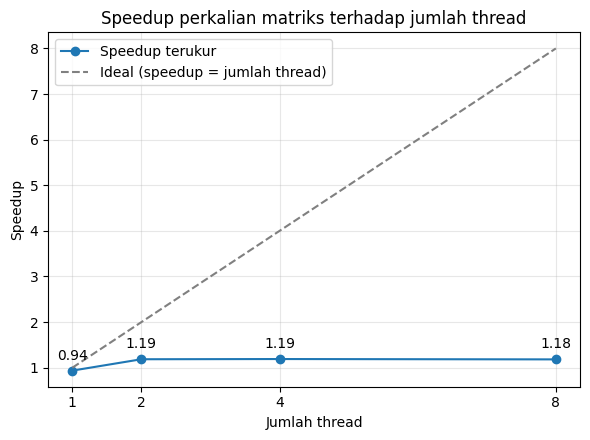

In [ ]:
plt.figure(figsize=(6, 4.5))
plt.plot(threads, speedup, "o-", label="Speedup terukur")
plt.plot(threads, threads, "--", color="gray", label="Ideal (speedup = jumlah thread)")
for t, sp in zip(threads, speedup):
    plt.annotate(f"{sp:.2f}", (t, sp), textcoords="offset points", xytext=(0, 8), ha="center")
plt.xlabel("Jumlah thread"); plt.ylabel("Speedup")
plt.title("Speedup perkalian matriks terhadap jumlah thread")
plt.xticks(threads); plt.grid(alpha=0.3); plt.legend(); plt.tight_layout()
plt.show()

### 3.2 Bilangan prima dan scheduling

Data mentah (`hasil/prima.txt`, format `kebijakan;thread;ulangan;keluaran`):

In [ ]:
PRIMA = """static;1;1;N=10000000 prima=664579 waktu=19.520
static;1;2;N=10000000 prima=664579 waktu=19.376
static;1;3;N=10000000 prima=664579 waktu=19.347
static;2;1;N=10000000 prima=664579 waktu=13.459
static;2;2;N=10000000 prima=664579 waktu=12.948
static;2;3;N=10000000 prima=664579 waktu=12.875
static;4;1;N=10000000 prima=664579 waktu=8.423
static;4;2;N=10000000 prima=664579 waktu=8.418
static;4;3;N=10000000 prima=664579 waktu=8.716
static;8;1;N=10000000 prima=664579 waktu=7.190
static;8;2;N=10000000 prima=664579 waktu=7.686
static;8;3;N=10000000 prima=664579 waktu=7.380
dynamic,1000;1;1;N=10000000 prima=664579 waktu=19.238
dynamic,1000;1;2;N=10000000 prima=664579 waktu=19.577
dynamic,1000;1;3;N=10000000 prima=664579 waktu=19.160
dynamic,1000;2;1;N=10000000 prima=664579 waktu=10.675
dynamic,1000;2;2;N=10000000 prima=664579 waktu=11.629
dynamic,1000;2;3;N=10000000 prima=664579 waktu=17.631
dynamic,1000;4;1;N=10000000 prima=664579 waktu=10.194
dynamic,1000;4;2;N=10000000 prima=664579 waktu=9.846
dynamic,1000;4;3;N=10000000 prima=664579 waktu=9.675
dynamic,1000;8;1;N=10000000 prima=664579 waktu=9.557
dynamic,1000;8;2;N=10000000 prima=664579 waktu=9.636
dynamic,1000;8;3;N=10000000 prima=664579 waktu=9.175
guided;1;1;N=10000000 prima=664579 waktu=21.848
guided;1;2;N=10000000 prima=664579 waktu=19.821
guided;1;3;N=10000000 prima=664579 waktu=19.828
guided;2;1;N=10000000 prima=664579 waktu=12.434
guided;2;2;N=10000000 prima=664579 waktu=12.569
guided;2;3;N=10000000 prima=664579 waktu=12.045
guided;4;1;N=10000000 prima=664579 waktu=9.515
guided;4;2;N=10000000 prima=664579 waktu=9.985
guided;4;3;N=10000000 prima=664579 waktu=9.466
guided;8;1;N=10000000 prima=664579 waktu=9.510
guided;8;2;N=10000000 prima=664579 waktu=9.936
guided;8;3;N=10000000 prima=664579 waktu=7.055"""
print(len(PRIMA.splitlines()), "baris")

36 baris


**Tabel 3.** Bilangan prima sampai 10⁷, waktu per kebijakan scheduling (detik, median). Speedup 8 thread = waktu 1 thread / waktu 8 thread pada kebijakan yang sama.

In [ ]:
waktu, benar_p, urutan = {}, {}, []
pola = re.compile(r"^([^;]+);(\d+);(\d+);.*prima=(\d+) waktu=([\d.]+)")
for baris in PRIMA.splitlines():
    m = pola.search(baris)
    k, t = m.group(1), int(m.group(2))
    if k not in urutan:
        urutan.append(k)
    waktu.setdefault((k, t), []).append(float(m.group(5)))
    benar_p[(k, t)] = benar_p.get((k, t), True) and int(m.group(4)) == 664579

tp = [1, 2, 4, 8]
med = {(k, t): statistics.median(waktu[(k, t)]) for k in urutan for t in tp}
rows = []
for k in urutan:
    ok = all(benar_p[(k, t)] for t in tp)
    rows.append([k.replace(",", ", ")] + [fmt(med[(k, t)]) for t in tp]
                + [fmt(med[(k, 1)] / med[(k, 8)], 2), "ya" if ok else "TIDAK"])
tabel(["Kebijakan", "1 thread", "2 thread", "4 thread", "8 thread", "Speedup 8 thread", "Hasil = 664.579?"], rows)

| Kebijakan | 1 thread | 2 thread | 4 thread | 8 thread | Speedup 8 thread | Hasil = 664.579? |
|---|---|---|---|---|---|---|
| static | 19,376 | 12,948 | 8,423 | 7,380 | 2,63 | ya |
| dynamic, 1000 | 19,238 | 11,629 | 9,846 | 9,557 | 2,01 | ya |
| guided | 19,828 | 12,434 | 9,515 | 9,510 | 2,08 | ya |


**Gambar 2.** Waktu 8 thread untuk ketiga kebijakan scheduling.

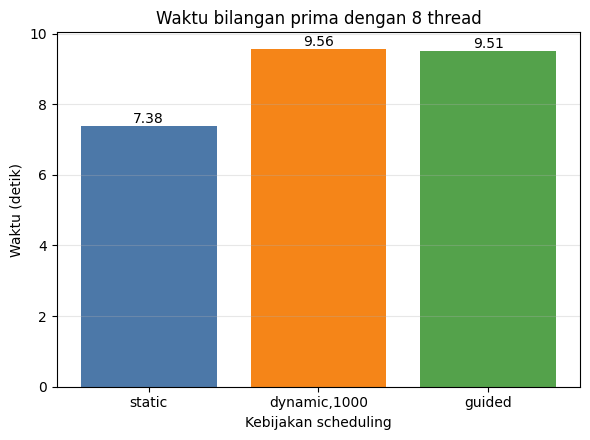

In [ ]:
w8 = [med[(k, 8)] for k in urutan]
plt.figure(figsize=(6, 4.5))
b = plt.bar(urutan, w8, color=["#4C78A8", "#F58518", "#54A24B"])
for x in b:
    plt.text(x.get_x() + x.get_width() / 2, x.get_height(), f"{x.get_height():.2f}", ha="center", va="bottom")
plt.xlabel("Kebijakan scheduling"); plt.ylabel("Waktu (detik)")
plt.title("Waktu bilangan prima dengan 8 thread")
plt.grid(axis="y", alpha=0.3); plt.tight_layout()
plt.show()

### 3.3 Percobaan tanpa `reduction`

Klausa `reduction` dihapus sementara dan program dijalankan 3 kali dengan 4 thread (`OMP_NUM_THREADS=4`).

In [ ]:
tanpa_reduction = [169045, 167606, 165873]
benar_nilai = 664579
rows = [[i + 1, f"{h:,}".replace(",", "."), f"{benar_nilai - h:,}".replace(",", "."),
         f"{100 * h / benar_nilai:.1f}%".replace(".", ",")] for i, h in enumerate(tanpa_reduction)]
tabel(["Run", "Hasil prima=", "Selisih dari 664.579", "Persentase dari nilai benar"], rows)

| Run | Hasil prima= | Selisih dari 664.579 | Persentase dari nilai benar |
|---|---|---|---|
| 1 | 169.045 | 495.534 | 25,4% |
| 2 | 167.606 | 496.973 | 25,2% |
| 3 | 165.873 | 498.706 | 25,0% |


Setelah percobaan, klausa `reduction(+:jumlah)` dikembalikan dan program kembali menghasilkan `prima=664579`.

## 4. Analisis

### Pertanyaan 1: perulangan yang diparalelkan dan variabel private

Yang diparalelkan adalah perulangan terluar dengan indeks `i` (baris matriks hasil). Variabel `i` otomatis private sebagai variabel perulangan paralel. Variabel `j`, `k`, dan `s` dideklarasikan di dalam region paralel sehingga juga private, jadi setiap thread punya akumulator `s` sendiri. Aman dari race condition karena setiap iterasi `i` hanya menulis ke baris `C[i][*]` miliknya sendiri, tidak ada dua thread yang menulis ke elemen yang sama, sedangkan matriks `A` dan `B` hanya dibaca. Kebenaran terbukti dari kolom *Benar?* pada Tabel 2 yang bernilai ya untuk semua jumlah thread.

### Pertanyaan 2: speedup dibandingkan ideal

Speedup ideal untuk 2, 4, dan 8 thread adalah 2, 4, dan 8. Speedup terukur hanya 1,186; 1,190; dan 1,182 (Tabel 2, Gambar 1), atau efisiensi 0,593; 0,298; dan 0,148. Peningkatan terjadi dari 1 ke 2 thread, lalu hampir datar. Dua faktor yang mungkin menjadi penyebab:

1. **Akses memori dan cache.** Matriks `B` dibaca per kolom sehingga banyak cache miss, dan perkalian menjadi dibatasi bandwidth memori yang dipakai bersama semua thread, bukan oleh kecepatan hitung.
2. **Sumber daya prosesor terbatas.** Mesin hanya punya 2 core fisik, dan thread tambahan hanya berbagi core lewat hyperthreading.

Faktor lain yang mungkin berperan adalah overhead pembuatan thread dan penurunan frekuensi CPU laptop saat beban tinggi. Waktu serial sendiri bervariasi antara 10,1 dan 13,8 detik antar run, yang menunjukkan kondisi mesin tidak sepenuhnya stabil. Pada 1 thread speedup 0,936 (di bawah 1) karena ada overhead OpenMP tanpa pembagian kerja.

### Pertanyaan 3: scheduling pada bilangan prima

Biaya memeriksa bilangan `x` sebanding dengan √x, sehingga iterasi di ujung rentang jauh lebih mahal daripada di awal. Total biaya sampai `x` tumbuh kira-kira sebanding dengan x^1,5, jadi dengan *static* (blok kontigu sama besar) blok terakhir menanggung sekitar 35% dari seluruh kerja pada 4 thread, atau sekitar 1,4 kali beban rata-rata. Thread lain selesai lebih awal lalu menunggu (load imbalance). Karena itu kebijakan yang membagi kerja secara adaptif (*dynamic*, *guided*) secara teori lebih seimbang.

Data menunjukkan hasil yang bercampur. Pada 2 thread, dynamic (11,629 s) dan guided (12,434 s) lebih cepat daripada static (12,948 s), sesuai teori. Namun pada 4 thread static tercepat (8,423 s dibanding 9,846 dan 9,515 s), dan pada 8 thread juga (7,380 s dibanding 9,557 dan 9,510 s). **Menurut data, kebijakan terbaik pada 8 thread adalah static** dengan speedup 2,63, dibanding 2,01 (dynamic) dan 2,08 (guided).

Penyebabnya tidak diuji langsung di praktikum ini. Dugaan: pada mesin dengan 2 core fisik, penjadwalan OS membagi waktu CPU antar thread sehingga ketimpangan beban static sebagian tertutupi, sementara dynamic dan guided menambah biaya pengambilan jatah. Faktor lain yang mungkin: ketiga kebijakan dijalankan berurutan (static lebih dulu), sehingga kondisi suhu laptop bisa ikut memengaruhi. Variasi antar run juga terlihat, misalnya dynamic 2 thread run ke-3 (17,631 s) dan guided 8 thread run ke-3 (7,055 s) yang menyimpang dari run lainnya; median dipakai untuk mengurangi pengaruhnya. Karena selisih antar kebijakan tidak besar dan faktor mesin ikut berpengaruh, kesimpulan ini berlaku untuk mesin yang dipakai.

### Pertanyaan 4: tanpa `reduction`

Tanpa `reduction`, variabel `jumlah` bersifat shared. Operasi `jumlah += ...` terdiri dari baca, tambah, dan tulis balik; ketika empat thread melakukannya bersamaan, beberapa thread membaca nilai lama yang sama lalu saling menimpa, sehingga banyak penambahan hilang (race condition, *lost update*). Hasil tiga run (169.045; 167.606; 165.873) hanya sekitar seperempat dari nilai benar 664.579 dan berbeda tiap run karena urutan eksekusi thread tidak dapat diprediksi. Waktu eksekusi tetap sekitar 6,8 sampai 7,6 detik, jadi yang rusak adalah kebenaran hasil, bukan kecepatan. Dengan `reduction(+:jumlah)` setiap thread memegang salinan sendiri yang dijumlahkan di akhir, sehingga hasil selalu 664.579.

### Pertanyaan 5: core fisik kurang dari 8

Mesin yang dipakai hanya punya 2 core fisik (4 core logis), sehingga 8 thread berarti oversubscription: jumlah thread melebihi jumlah core logis dan OS harus membagi waktu CPU antar thread (context switching). Pada perkalian matriks speedup pada 2, 4, dan 8 thread hampir sama (1,186; 1,190; 1,182), artinya thread tambahan tidak memberi keuntungan. Pada program prima, 8 thread hanya memperbaiki waktu sedikit dari 4 thread pada static (8,423 menjadi 7,380 s) dan hampir tidak berubah pada dynamic dan guided (9,846 menjadi 9,557 s; 9,515 menjadi 9,510 s). Speedup 8 thread sebesar 2,0 sampai 2,6 jauh di bawah 8, dengan sebagian besar keuntungan sudah dicapai pada 2 sampai 4 thread.

## 5. Kesimpulan

Perkalian matriks berhasil diparalelkan dengan memparalelkan perulangan baris, hasil benar pada semua jumlah thread, tetapi speedup terbatas sekitar 1,19 pada mesin 2 core fisik dengan beban yang dibatasi akses memori. Pada bilangan prima, `reduction` wajib untuk hasil benar; tanpanya hasil menyimpang jauh karena race condition. Dalam percobaan ini static memberi waktu terbaik pada 4 dan 8 thread, sedangkan pada 2 thread dynamic dan guided lebih cepat, sesuai teori beban tidak seragam. Hasil sangat dipengaruhi jumlah core fisik dan kondisi mesin, sehingga angka pada laporan ini berlaku untuk lingkungan pada Tabel 1.

## Lampiran

### A. Kode `src/matmul.c`

```c
/* matmul.c - Praktikum 1 */
#include <stdio.h>
#include <stdlib.h>
#include <math.h>
#include <omp.h>

static void isi_acak(double *m, int n, unsigned seed) {
    srand(seed);
    for (long i = 0; i < (long)n * n; i++) m[i] = (double)rand() / RAND_MAX;
}

/* Versi serial: acuan kebenaran dan waktu. Jangan diubah. */
static void matmul_serial(const double *A, const double *B, double *C, int n) {
    for (int i = 0; i < n; i++)
        for (int j = 0; j < n; j++) {
            double s = 0.0;
            for (int k = 0; k < n; k++) s += A[(long)i * n + k] * B[(long)k * n + j];
            C[(long)i * n + j] = s;
        }
}

static void matmul_paralel(const double *A, const double *B, double *C, int n) {
    #pragma omp parallel for
    for (int i = 0; i < n; i++)
        for (int j = 0; j < n; j++) {
            double s = 0.0;
            for (int k = 0; k < n; k++) s += A[(long)i * n + k] * B[(long)k * n + j];
            C[(long)i * n + j] = s;
        }
}

static int sama(const double *X, const double *Y, long len, double tol) {
    for (long i = 0; i < len; i++) {
        double skala = fabs(Y[i]) > 1.0 ? fabs(Y[i]) : 1.0;
        if (fabs(X[i] - Y[i]) > tol * skala) return 0;
    }
    return 1;
}

int main(int argc, char **argv) {
    int n = (argc > 1) ? atoi(argv[1]) : 1024;
    long len = (long)n * n;
    double *A = malloc(len * sizeof(double)), *B = malloc(len * sizeof(double));
    double *Cs = malloc(len * sizeof(double)), *Cp = malloc(len * sizeof(double));
    isi_acak(A, n, 1);
    isi_acak(B, n, 2);
    double t0 = omp_get_wtime();
    matmul_serial(A, B, Cs, n);
    double t1 = omp_get_wtime();
    matmul_paralel(A, B, Cp, n);
    double t2 = omp_get_wtime();
    printf("n=%d thread=%d serial=%.3f paralel=%.3f benar=%s\n",
           n, omp_get_max_threads(), t1 - t0, t2 - t1,
           sama(Cp, Cs, len, 1e-9) ? "ya" : "TIDAK");
    free(A); free(B); free(Cs); free(Cp);
    return 0;
}
```

### B. Kode `src/prima.c`

```c
/* prima.c - Praktikum 1 */
#include <stdio.h>
#include <omp.h>

static int is_prima(long x) {
    if (x < 2) return 0;
    for (long d = 2; d * d <= x; d++)
        if (x % d == 0) return 0;
    return 1;
}

int main(void) {
    const long N = 10000000; /* 10^7 */
    long jumlah = 0;
    double t0 = omp_get_wtime();

    #pragma omp parallel for reduction(+:jumlah) schedule(runtime)
    for (long x = 2; x <= N; x++)
        jumlah += is_prima(x);

    double t1 = omp_get_wtime();
    printf("N=%ld prima=%ld waktu=%.3f\n", N, jumlah, t1 - t0);
    return 0;
}
```

### C. Cara mengulang eksperimen

```bash
gcc -O2 -fopenmp src/matmul.c -o matmul -lm
gcc -O2 -fopenmp src/prima.c -o prima

for t in 1 2 4 8; do
  for r in 1 2 3; do
    OMP_NUM_THREADS=$t ./matmul 1024 >> hasil/matmul.txt
  done
done

for s in "static" "dynamic,1000" "guided"; do
  for t in 1 2 4 8; do
    for r in 1 2 3; do
      echo -n "$s;$t;$r;" >> hasil/prima.txt
      OMP_SCHEDULE="$s" OMP_NUM_THREADS=$t ./prima >> hasil/prima.txt
    done
  done
done
```